In [ ]:
import ee
import geemap
import xarray as xr
!pip install xee
import xee

In [ ]:
1 ee.Authenticate()
2 ee.Initialize(
    project = 'shining-axis-461118-t5',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

In [ ]:
map=geemap.Map(basemap='SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], widget=SearchDataGUI(childr…

In [ ]:
roi=map.draw_last_feature.geometry()

In [ ]:
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          85.179925,
                          27.539926
                        ],
                        [
                          85.179925,
                          27.846353
                        ],
                        [
                          85.531508,
                          27.846353
                        ],
                        [
                          85.531508,
                          27.539926
                        ],
                        [
                          85.179925,
                          27.539926
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [ ]:
daily_col= (
    ee.ImageCollection("projects/sat-io/open-datasets/GHAP/GHAP_D1K_PM25")
    .filterDate('2017','2022')
)

In [ ]:
daily_col

In [ ]:
daily_ds=xr.open_dataset(
    daily_col,
    engine='ee',
    crs='EPSG:4326',
    geometry=roi,
    scale=0.001
)

In [ ]:
daily_ds

<xarray.Dataset> Size: 785MB
Dimensions:  (time: 1822, lon: 352, lat: 306)
Coordinates:
  * time     (time) datetime64[ns] 15kB 2017-01-01 2017-01-02 ... 2021-12-31
  * lon      (lon) float64 3kB 85.18 85.18 85.18 85.18 ... 85.53 85.53 85.53
  * lat      (lat) float64 2kB 27.54 27.54 27.54 27.54 ... 27.84 27.84 27.85
Data variables:
    b1       (time, lon, lat) float32 785MB ...
Attributes:
    crs:      EPSG:4326

In [ ]:
daily_ave=daily_ds.mean(dim=['lat','lon'])*0.1

In [ ]:
daily_ave

<xarray.Dataset> Size: 22kB
Dimensions:  (time: 1822)
Coordinates:
  * time     (time) datetime64[ns] 15kB 2017-01-01 2017-01-02 ... 2021-12-31
Data variables:
    b1       (time) float32 7kB 6.613 5.65 4.982 4.902 ... 3.552 3.402 3.813

In [ ]:
daily_df=daily_ave.to_dataframe()

In [ ]:
daily_df.to_csv('dailypm2.5.csv')

<Axes: xlabel='time'>

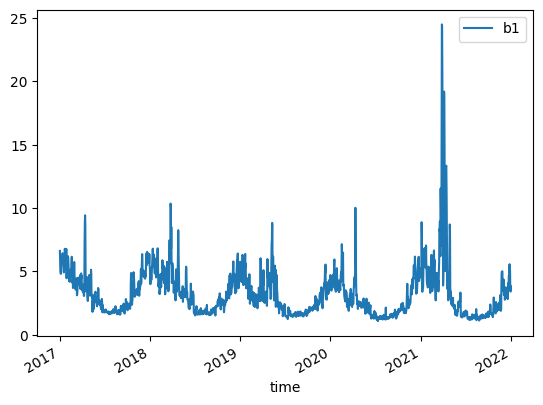

In [ ]:
daily_df.plot()

In [ ]:
monthly_col=(
    ee.ImageCollection("projects/sat-io/open-datasets/GHAP/GHAP_M1K_PM25")
    .filterDate('2017','2023')

)

In [ ]:
monthly_ds=xr.open_dataset(
    monthly_col,
    engine='ee',
    crs='EPSG:4326',
    geometry=roi,
    scale=0.001
)

In [ ]:
monthly_ds

<xarray.Dataset> Size: 31MB
Dimensions:  (time: 72, lon: 352, lat: 306)
Coordinates:
  * time     (time) datetime64[ns] 576B 2017-01-01 2017-02-01 ... 2022-12-01
  * lon      (lon) float64 3kB 85.18 85.18 85.18 85.18 ... 85.53 85.53 85.53
  * lat      (lat) float64 2kB 27.54 27.54 27.54 27.54 ... 27.84 27.84 27.85
Data variables:
    b1       (time, lon, lat) float32 31MB ...
Attributes:
    crs:      EPSG:4326

In [ ]:
month_mean=monthly_ds.groupby('time.month').mean('time')*0.1

In [ ]:
import matplotlib.pyplot as plt

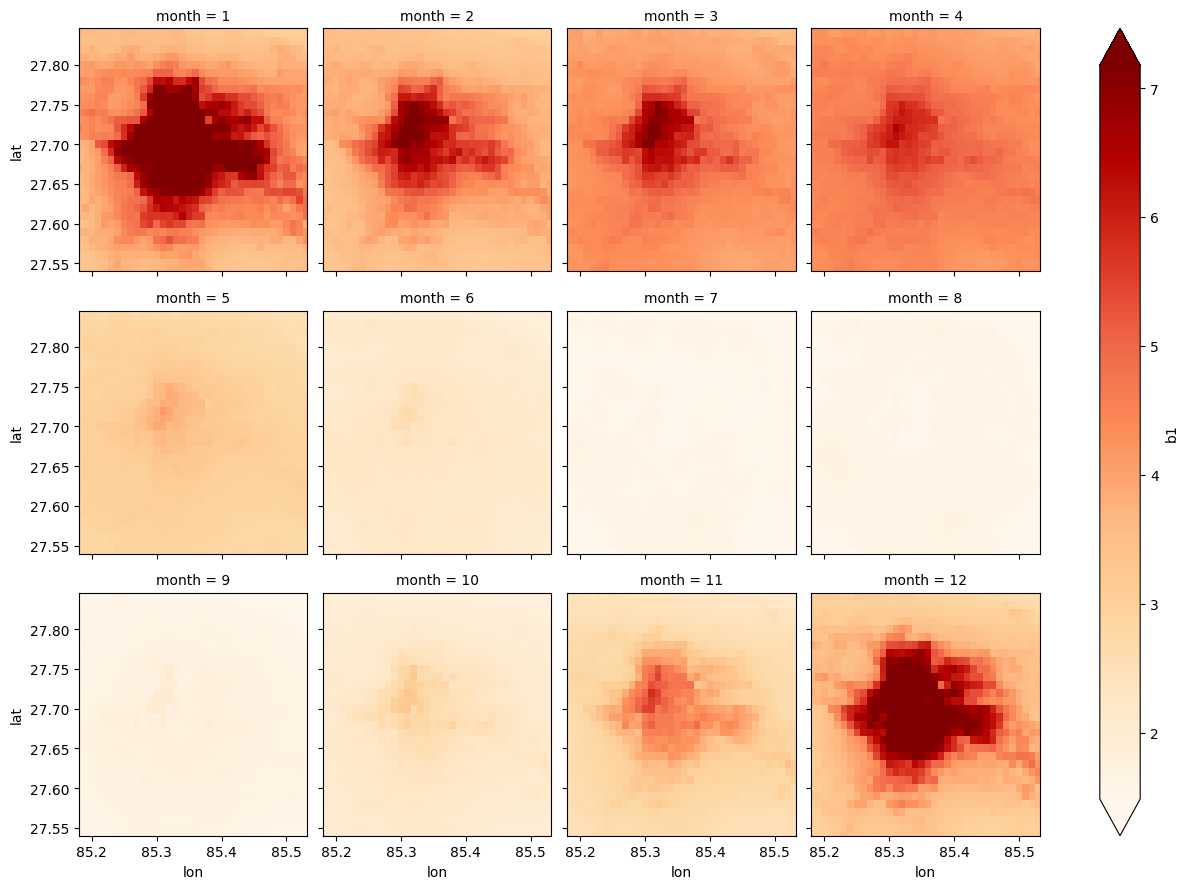

In [ ]:
month_mean.b1.plot(
    x='lon',
    y='lat',
    col='month',
    robust=True,
    col_wrap=4,
    cmap='OrRd'
)

plt.savefig("montyhpm2.5ktm.png",dpi=600, bbox_inches='tight')

In [ ]:
monthly_ave= monthly_ds.mean(dim=['lat','lon'])*0.1

In [ ]:
monthly_ave

<xarray.Dataset> Size: 864B
Dimensions:  (time: 72)
Coordinates:
  * time     (time) datetime64[ns] 576B 2017-01-01 2017-02-01 ... 2022-12-01
Data variables:
    b1       (time) float32 288B 5.666 5.042 4.114 4.328 ... 1.784 2.56 4.342

In [ ]:
monthly_df=monthly_ave.to_dataframe()

<Axes: xlabel='time'>

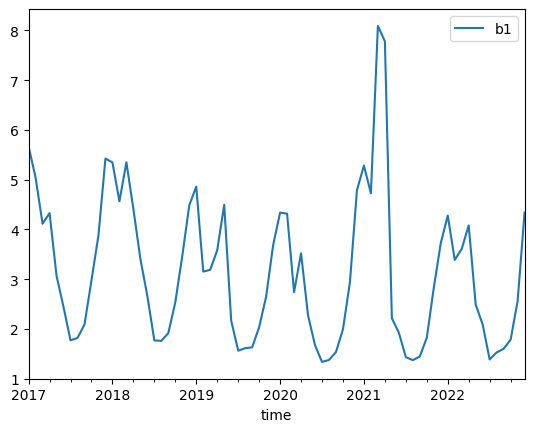

In [ ]:
monthly_df.plot()

In [ ]:
annual_ds=monthly_ds.resample(time='YE').mean('time')*0.1

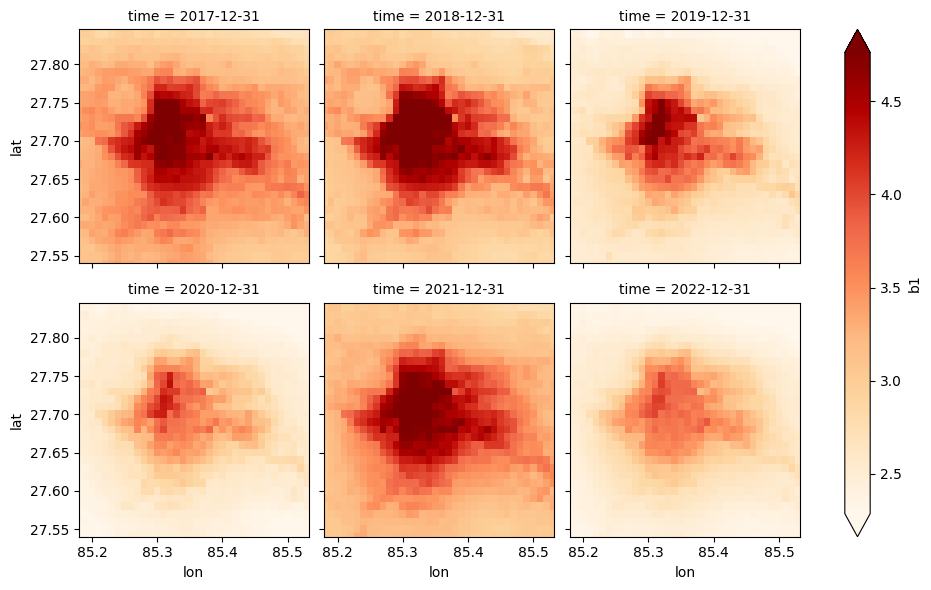

In [ ]:
annual_ds.b1.plot(
    x='lon',
    y='lat',
    col='time',
    robust=True,
    col_wrap=3,
    cmap='OrRd'
)

plt.savefig("yearlypm2.5ktm.png",dpi=600, bbox_inches='tight')